# Assignment 11: Spatial community composition in California

## BIO597 Spatial Analysis of Biodiversity

Repeat the [Lab11](../labs/Lab11-SpatialCommunityComposition.ipynb) analysis for
California. How do grid grain, geographic distance, and climate affect our view
of amphibian communities across this larger and environmentally varied state?

Use **20, 40, and 80 km cells**. Follow the lab's sequence: community matrices,
richness, distance decay, neighboring-community differences, GDM at each grain,
and a PCA map/biplot of all 19 GDM-transformed bioclimatic predictors. You may reuse the lab's analysis
code. Spatial preparation helpers are supplied below.

Submit this notebook with figures, summary tables, short answers, and a
**400–600 word synthesis**. Cite the GBIF download DOI and the boundary and
climate sources.

## Inputs and environment

Run from `docs/assignments` using the Lab11 environment, including `gdmbayes`,
GeoPandas and Rasterio.

| Input | Path from this notebook |
| --- | --- |
| California boundary, including islands | `../data/CA_ShapeFiles/California_State_Boundary.shp` |
| GBIF amphibian occurrences | `../data/CA_amphibians.geojson` |
| All 19 clipped WorldClim layers | `../data/bioclim_CA` |

All inputs are provided. The occurrence GeoJSON is a reproducible random
sample of California records from the GBIF download, reduced to about **20 MB**
and using the same fields as the Maine data. See the
[California data notes](../data/CA_data_README.md) for filtering, sample size,
and provenance. Record the download DOI here:

*GBIF download DOI:* [10.15468/dl.wbj54a](https://doi.org/10.15468/dl.wbj54a)

## 1. Load and inspect the California data

Use **California Albers (EPSG:3310)** for the grid and approximate geographic
distances in meters. California spans more than one UTM zone, so do not reuse
Maine's UTM projection or grid origin.

The occurrence file contains amphibian detections within the California
boundary. It was randomly sampled after clipping. Drop records without a species
name before constructing communities. The six fields
match Maine's data: GBIF ID, species, longitude, latitude, coordinate uncertainty,
and year. Random downsampling can remove observations of rarely recorded species.

In [6]:
pip install gdmbayes

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 85.7 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 75.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 85.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 98.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 94.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 71.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 57.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 619.6/619.6 kB 29.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 38.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 91.

In [2]:
pip install rasterio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.1/39.1 MB 107.3 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [rasterio]1/2 [rasterio]
Note: you may need to restart the kernel to use updated packages.


In [19]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.mask import mask
from shapely.geometry import box
from scipy.spatial.distance import pdist, squareform
from gdmbayes import GDM

CRS = "EPSG:3310"
GRAINS = [20, 40, 80]
MIN_RECORDS = 1
CLIMATE_DIR = Path("../data/bioclim_CA")
OUTPUT = Path("outputs/Assignment11")
OUTPUT.mkdir(parents=True, exist_ok=True)

california = gpd.read_file("../data/CA_ShapeFiles/California_State_Boundary.shp")
california = california.to_crs(CRS).dissolve()
records = gpd.read_file("../data/CA_amphibians.geojson").to_crs(CRS)
print("Input records:", len(records))
records = records.dropna(subset=["species"])
records = records[records.species != ""]
records = gpd.clip(records, california)
print("Sampled records with species names:", len(records))
print("Species labels:", records.species.nunique())

Input records: 71578
Sampled records with species names: 62829
Species labels: 89


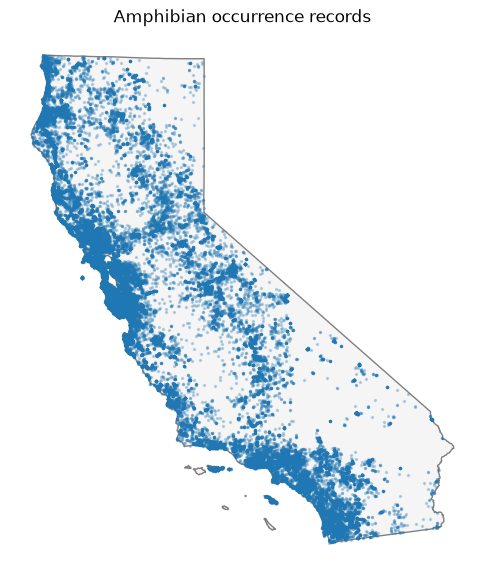

Total records:  62829
[2021. 2023. 2024. 1979. 1976. 2025. 2022. 2020. 1928. 2019. 2003. 2005.
 2000. 2017. 2001. 1995. 2018. 1972. 1980. 1997. 1974. 1998. 2026. 1990.
 1929. 1984. 1978. 1973. 1927. 1915. 1923. 1970. 1971. 1894. 1981. 2013.
 1977. 2014. 1947.   nan 1966. 1987. 1909. 1930. 1955. 1950. 2004. 1999.
 2002. 2012. 1932. 1919. 1963. 1908. 1921. 2015. 1951. 1946. 1975. 1949.
 1961. 2016. 1964. 1944. 2007. 1957. 1958. 1920. 1968. 1959. 1945. 2011.
 1942. 1985. 1960. 1962. 1934. 1926. 2006. 1956. 1982. 1969. 1931. 1991.
 1967. 1938. 1952. 1924. 1912. 2010. 2008. 2009. 1916. 1905. 1954. 1989.
 1933. 1889. 1948. 1996. 1953. 1992. 1983. 1935. 1936. 1965. 1893. 1939.
 1941. 1917. 1993. 1994. 1910. 1914. 1922. 1911. 1937. 1918. 1892. 1897.
 1940. 1943. 1925. 1906. 1875. 1913. 1888. 1903. 1907. 1904. 1988. 1986.
 1891. 1879. 1895. 1901. 1900. 1899. 1872. 1902. 1896. 1898. 1876. 1859.
 1884. 1878. 1860. 1873.]
18789    7270407.00
29512    1982539.00
40577    1982403.00
20357    1980457

In [20]:
# Map the boundary and occurrence points.
ax = california.plot(color="whitesmoke", edgecolor="gray", figsize=(6, 7))
records.plot(ax=ax, markersize=2, alpha=0.25)
ax.set_title("Amphibian occurrence records")
ax.set_axis_off()
plt.show()
# Inspect record years and coordinateUncertaintyInMeters.
print("Total records: ", len(records))
print(records["year"].unique())
print(records["coordinateUncertaintyInMeters"].sort_values(ascending=False).head(20)) # some very high uncertainty
# Consider sampling gaps, repeated locations, and coordinate uncertainty.
records = records[records["coordinateUncertaintyInMeters"] < 200] # only keep records with uncertainty <200
print("Records with uncertainty <200: ", len(records))

**Interpretation:** Where are observations concentrated or sparse? Which parts
of California might be especially difficult to characterize from these data?
Explain why repeated records, uncertain coordinates, and unresolved species
names matter for a site-by-species matrix.

*Your answer:* The observations are pretty concentrated to the western part of the state, especially along the coast where human population densities are high. The northeastern and southeastern parts of the state will be difficult to characterize from these data because they are quite sparse. Repeated records needed to be removed because they only represent one true observation and could inflate the estimated abundance of that species in that location. Uncertain coordinates should also be filtered out becuase they do not represent accurate locations of the record, so they could falsely attribute a record to a location where the species didn't actually occur. Finally, unresolved species need to be filtered out because they should not count toward records of a particular species if they are uncertain.

## 2. Aggregate records to sites

The helper follows Lab11 but uses the California boundary and a new shared grid
origin. Finer cells nest within coarser cells. Only cells meeting `MIN_RECORDS`
become sites; missing cells are not treated as zero-richness communities.

Map outlines are clipped to the state, but geographic distances use the full
square centers. Coastal and island cells can contain less land than interior
cells of the same nominal grain.

In [21]:
origin_width = max(GRAINS) * 1000
x0 = np.floor(california.total_bounds[0] / origin_width) * origin_width
y0 = np.floor(california.total_bounds[1] / origin_width) * origin_width


def grid_communities(grain_km):
    width = grain_km * 1000
    points = records.copy()
    points["col"] = ((points.geometry.x - x0) // width).astype(int)
    points["row"] = ((points.geometry.y - y0) // width).astype(int)
    points["site_id"] = points.col.astype(str) + "_" + points.row.astype(str)
    community = pd.crosstab(points.site_id, points.species)
    cell_locations = points[["site_id", "col", "row"]].drop_duplicates()
    cells = []
    for cell in cell_locations.itertuples():
        x = x0 + cell.col * width
        y = y0 + cell.row * width
        cells.append({"site_id": cell.site_id, "xc": x + width / 2,
                      "yc": y + width / 2, "geometry": box(x, y, x + width, y + width)})
    sites = gpd.GeoDataFrame(cells, crs=CRS).set_index("site_id")
    sites = gpd.clip(sites, california).sort_index()
    community = community.reindex(sites.index)
    sites["n_records"] = community.sum(axis=1)
    sites["richness"] = (community > 0).sum(axis=1)
    sites = sites[sites.n_records >= MIN_RECORDS].copy()
    return sites, community.loc[sites.index]

In [22]:
sites_by_grain = {}
communities = {}
grain_summary = pd.DataFrame()

# Loop over GRAINS and call grid_communities(grain).
for grain in GRAINS:
    sites, community = grid_communities(grain)
# Store sites_by_grain[grain] and communities[grain], as in Lab11.
    sites_by_grain[grain] = sites
    communities[grain] = community
# Summarize n_sites, n_records, mean_richness, and median_records_per_site.
    grain_summary.loc[grain, "n_sites"] = len(sites)
    grain_summary.loc[grain, "n_records"] = sites.n_records.sum()
    grain_summary.loc[grain, "mean_richness"] = sites.richness.mean()
    grain_summary.loc[grain, "median_records_per_site"] = sites.n_records.median()
# Display grain_summary and the first rows of communities[40].
grain_summary.index.name = "grain_km"
display(grain_summary)
display(communities[20].head())

,n_sites,n_records,mean_richness,median_records_per_site
grain_km,,,,
20,727.0,24374.0,3.447043,7.0
40,253.0,24374.0,5.075099,23.0
80,81.0,24374.0,7.950617,93.0


species,Ambystoma californiense,Ambystoma gracile,Ambystoma macrodactylum,Ambystoma mavortium,Ambystoma tigrinum,Amerana aurora,Amerana boylii,Amerana cascadae,Amerana draytonii,Amerana muscosa,...,Pseudacris regilla,Rhyacotriton variegatus,Scaphiopus couchii,Spea hammondii,Spea intermontana,Taricha granulosa,Taricha rivularis,Taricha sierrae,Taricha torosa,Xenopus laevis
site_id,,,,,,,,,,,,,,,,,,,,,
10_26,0,0,0,0,0,0,0,0,0,0,...,76,0,0,0,0,44,0,0,44,0
10_27,0,0,0,0,0,0,0,0,0,0,...,69,0,0,0,0,43,0,0,102,0
10_28,2,0,0,0,0,0,0,0,0,0,...,81,0,0,0,0,25,2,0,132,0
10_29,0,0,0,0,0,0,0,0,0,0,...,8,0,0,0,0,0,0,0,0,0
10_30,0,0,0,0,0,0,0,0,0,0,...,25,0,0,0,0,1,0,0,44,0


## 3. Richness and sampling maps

Plot richness for all three grains using one shared color scale. Make a second
comparison of record counts and richness at 20 km. Use `california` as the
background layer when adapting the lab's mapping cells.

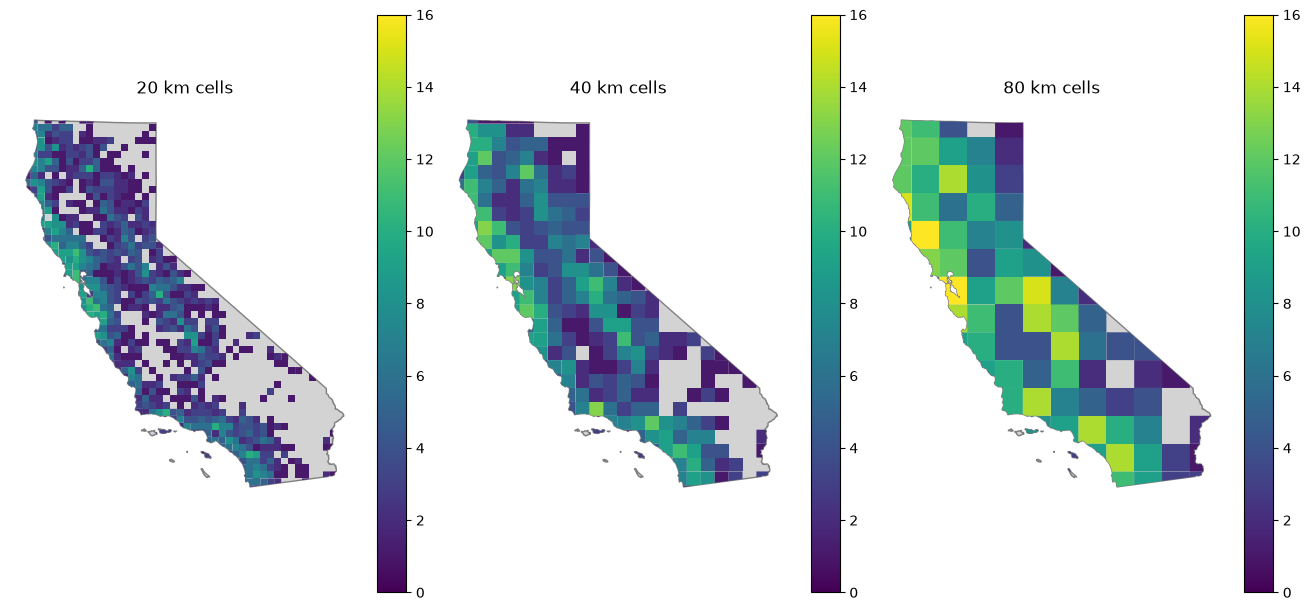

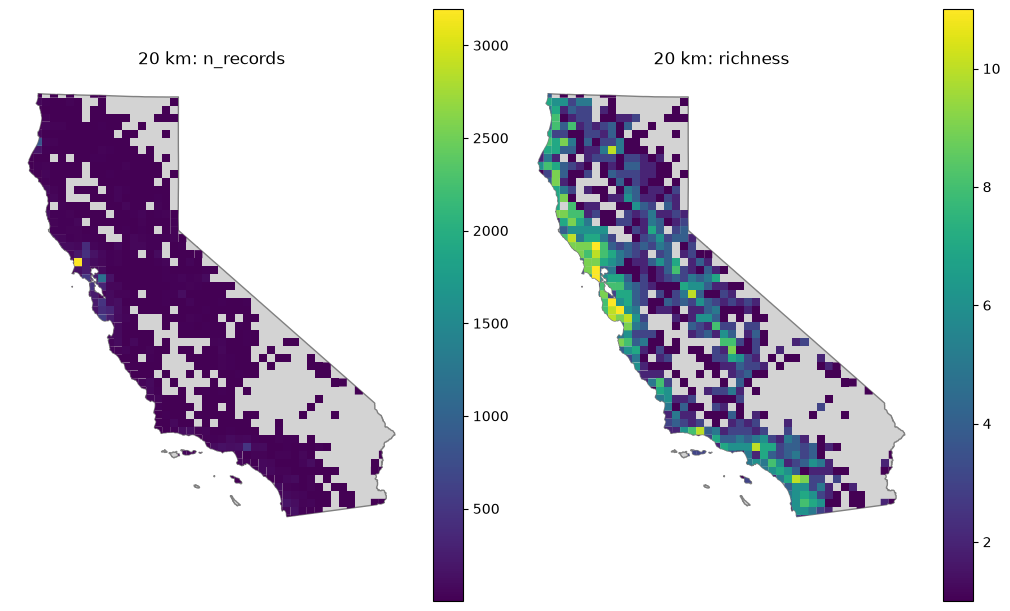

In [27]:
# Create and save the three richness maps with a common color scale.
max_richness = max(sites.richness.max() for sites in sites_by_grain.values())
fig, axes = plt.subplots(1, 3, figsize=(13, 6), layout="constrained")
for ax, grain in zip(axes, GRAINS):
    california.plot(ax=ax, color="lightgray", edgecolor="gray")
    sites_by_grain[grain].plot(ax=ax, column="richness", cmap="viridis",
                              vmin=0, vmax=max_richness, legend=True)
    ax.set_title(f"{grain} km cells")
    ax.set_axis_off()
fig.savefig(OUTPUT / "richness_by_grain.png", dpi=150)
plt.show()

# Compare n_records and richness at 20 km.
fig, axes = plt.subplots(1, 2, figsize=(10, 6), layout="constrained")
for ax, column in zip(axes, ["n_records", "richness"]):
    california.plot(ax=ax, color="lightgray", edgecolor="gray")
    sites_by_grain[20].plot(ax=ax, column=column, legend=True)
    ax.set_title(f"20 km: {column}")
    ax.set_axis_off()
plt.show()

**Interpretation:** Which richness patterns persist across grains? Which become
more or less apparent? How much might the patterns reflect aggregation,
reporting effort, or differences in the amount of land within a cell?

*Your answer:* The general pattern of high richness near the coast and in the high elevations in the center of the state persist across grains, but the diversity estimates become more similar (and higher) across cells at the 80km grain. The high diversity estimates in each 80km cell are definitely the result of aggregation and may also be due to more land within each cell. Comparing n_records and richness in 20km cells, there does seem to be higher n_records in the bay area associated with high richness, but other parts of the state with high richness, such as the southern coastline and mountians, have high richness but not greatly higher n_records. I would like to see n_records on a log scale, though.

## 4. Distance decay of similarity

Use presence/absence and **Jaccard dissimilarity**. Similarity is `1 - Jaccard`.
The helpers below retain matching site order and summarize similarity in
100 km distance bands, allowing for California's larger extent.

Plot all pairs and their distance-band means for each grain. Keep similarity
axes fixed at 0–1. Report the descriptive Spearman distance–similarity
correlation, without treating pairs that share sites as independent replicates.

In [28]:
def community_pairs(sites, community):
    presence = community.loc[sites.index] > 0
    dissimilarity = pdist(presence, metric="jaccard")
    distance_km = pdist(sites[["xc", "yc"]]) / 1000
    return pd.DataFrame({"distance_km": distance_km,
                         "jaccard": dissimilarity,
                         "similarity": 1 - dissimilarity})


def distance_bands(pairs):
    rows = []
    for lower in range(0, 1600, 100):
        in_band = pairs[(pairs.distance_km >= lower) & (pairs.distance_km < lower + 100)]
        if len(in_band) == 0:
            continue
        rows.append({"distance_km": in_band.distance_km.mean(),
                     "mean_similarity": in_band.similarity.mean(),
                     "n_pairs": len(in_band)})
    return pd.DataFrame(rows)

,distance_km,jaccard,similarity
0,20.0,0.00,1.00
1,40.0,0.25,0.75
2,60.0,0.70,0.30
3,80.0,0.20,0.80
4,100.0,0.30,0.70


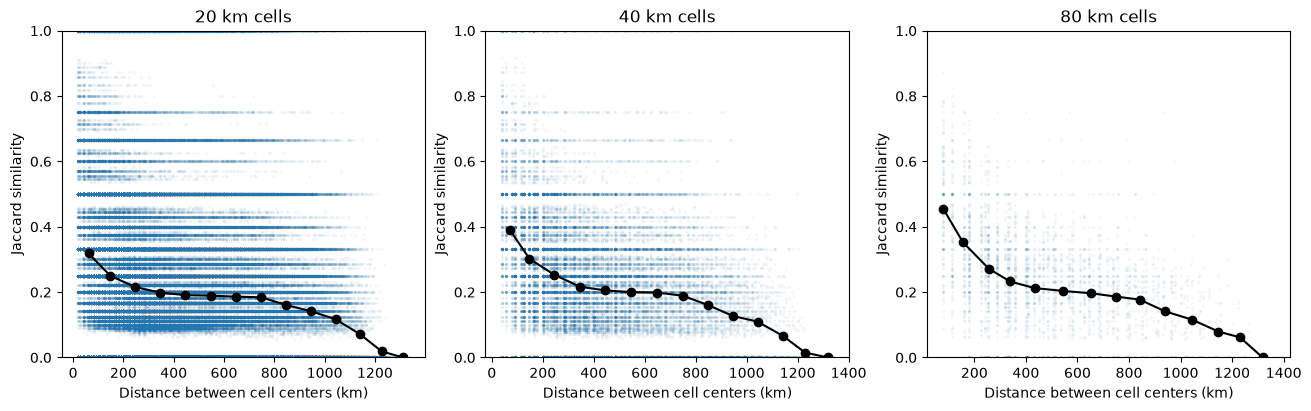

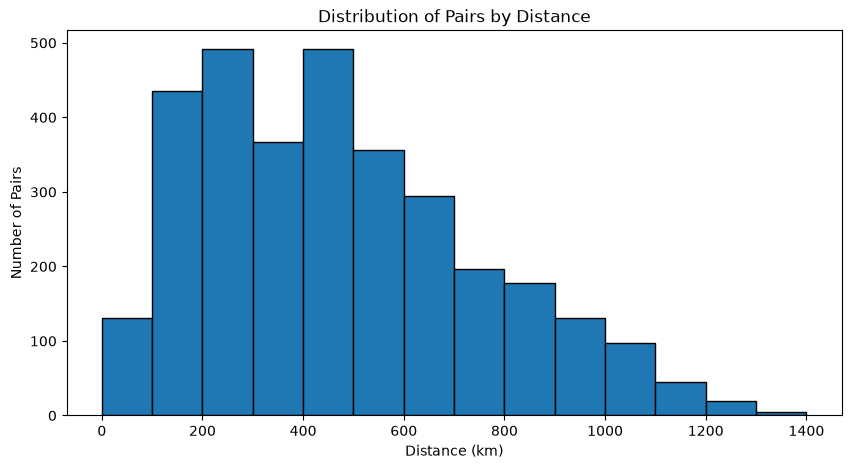

In [36]:
pairs_by_grain = {}
for grain in GRAINS:
    pairs_by_grain[grain] = community_pairs(sites_by_grain[grain], communities[grain])
display(pairs_by_grain[20].head())

binned_decay = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")

# For each grain, calculate community_pairs and distance_bands.
for ax, grain in zip(axes, GRAINS):
    pairs = pairs_by_grain[grain]
    bands = distance_bands(pairs)

# Make distance-decay plots and calculate the descriptive correlation.
    binned_decay[grain] = bands
    ax.scatter(pairs.distance_km, pairs.similarity, s=2, alpha=0.03)
    ax.plot(bands.distance_km, bands.mean_similarity, color="black", marker="o")
    ax.set(title=f"{grain} km cells", xlabel="Distance between cell centers (km)",
           ylabel="Jaccard similarity", ylim=(0, 1))
    grain_summary.loc[grain, "distance_similarity_rho"] = pairs.distance_km.corr(
        pairs.similarity, method="spearman")
fig.savefig(OUTPUT / "distance_decay_by_grain.png", dpi=150)
plt.show()


# Inspect n_pairs in the most distant bands before interpreting their means.
max_dist = pairs["distance_km"].max()
bins = np.arange(0, max_dist + 100, 100)

plt.figure(figsize=(10, 5))
plt.hist(pairs["distance_km"], bins=bins, edgecolor="black")
plt.xlabel("Distance (km)")
plt.ylabel("Number of Pairs")
plt.title("Distribution of Pairs by Distance")
plt.show()

**Interpretation:** Does similarity decline steadily, level off, or show another
pattern? How does the relationship change with grain? Explain at least two
biological or sampling explanations. Could nested species lists contribute to
Jaccard dissimilarity without species replacement?

*Your answer:* Similarity declines rapidly in the first ~300 km, then slows between 400-800 km, then rapidly declines again. This relationship is consistent among grain sizes. The largest distances have slightly lower-skewed numbers of pairs, but the histogram is not *greatly* skewed. It is biologically feasible that communities are more similar closer together, especially because California contains such a diversity of ecosystems from ocean to desert to mountains. It is also possible that higher sampling effort near the coast led to higher numbers of records compared to those in the desert, leading to biased estimates of dissimilarity. It is very possible that nested species lists contribute to dissimilarity without replacement. If a desert community only contains a subset of the species present in the mountian community, then the desert community has 0 unique species and a high Jaccard dissimilarity, even if no species replacement occurs.

## 5. Local differences among communities

Reuse the lab's neighbor comparison: mean Jaccard dissimilarity to sampled
cells within **1.5 cell widths**, excluding the focal cell. Map the results for
all three grains with one 0–1 color scale. Leave cells with no sampled neighbors
as missing.

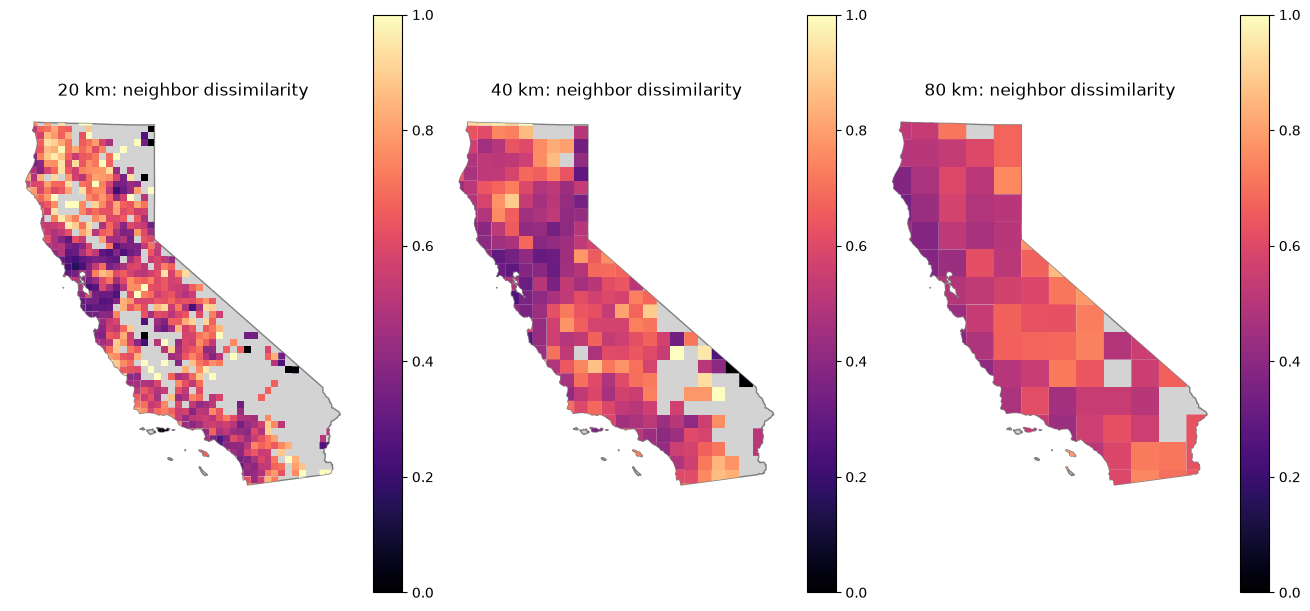

In [39]:
# Use squareform on each grain's distance and dissimilarity vectors.
for grain in GRAINS:
    sites = sites_by_grain[grain]
    pairs = pairs_by_grain[grain]
    distances = squareform(pairs.distance_km.to_numpy())
    dissimilarities = squareform(pairs.jaccard.to_numpy())
    local_difference = []

# Calculate neighbor_dissimilarity for each sampled cell.
    for i in range(len(sites)):
        neighbors = (distances[i] > 0) & (distances[i] <= 1.5 * grain)
        if neighbors.any():
            local_difference.append(dissimilarities[i, neighbors].mean())
        else:
            local_difference.append(np.nan)
    sites["neighbor_dissimilarity"] = local_difference

# Map and save the three results.
fig, axes = plt.subplots(1, 3, figsize=(13, 6), layout="constrained")
for ax, grain in zip(axes, GRAINS):
    california.plot(ax=ax, color="lightgray", edgecolor="gray")
    sites_by_grain[grain].plot(ax=ax, column="neighbor_dissimilarity", cmap="magma",
                              vmin=0, vmax=1, legend=True)
    ax.set_title(f"{grain} km: neighbor dissimilarity")
    ax.set_axis_off()
fig.savefig(OUTPUT / "neighbor_dissimilarity_by_grain.png", dpi=150)
plt.show()

In [53]:
print(sites.sort_values(by="neighbor_dissimilarity", ascending=False).head())

               xc        yc  \
site_id                       
6_8      120000.0   40000.0   
6_1      120000.0 -520000.0   
7_7      200000.0  -40000.0   
5_9       40000.0  120000.0   
4_11     -40000.0  280000.0   

                                                  geometry  n_records  \
site_id                                                                 
6_8      POLYGON ((80000 0, 80000 38811.832, 80085.581 ...          1   
6_1      MULTIPOLYGON (((133573.19 -560000, 133453.197 ...         17   
7_7      POLYGON ((160000 -80000, 160000 -31519.316, 16...         21   
5_9      POLYGON ((0 80000, 0 109214.975, 4210.765 1055...          3   
4_11     POLYGON ((-80000 240000, -80000 320000, 0 3200...         16   

         richness  neighbor_dissimilarity  
site_id                                    
6_8             1                0.858095  
6_1             3                0.790873  
7_7             2                0.782853  
5_9             2                0.775556  
4_11  

**Interpretation:** Where are neighboring recorded communities most different?
Choose two contrasting sites and inspect their species lists and record totals.
Why is this not a map of pure species replacement or turnover per kilometer?

*Your answer:* Neighboring recorded communities are most different in the far north (seems to correspond to high elevation forests) and in the central mountains (Sierra Nevada range), but there are really high dissimilarity cells all over the place. Site 6_8 has the highest dissimilarity and only has one record (!), whereas 6_1 has the second highest dissimilarity and has 17 records. This shows that sites wiht few records will have high dissimilarity due to low record counts (which could lead to nested species lists or turnover) and not due to community diversity.

## 6. Summarize site climate

Use **all 19 bioclimatic variables**, matching the revised Lab11 and its
predictor names. Each site's climate is the mean of valid raster pixels
intersecting its land area. Edge pixels are included equally; this is an
approximate zonal mean, not an exact area-weighted average.

Inspect the ranges and correlations of all predictors. For orientation, map
`temperature_c` (BIO1) and `precip` (BIO12) at 40 km. These are example maps;
**all 19 variables enter every full GDM and the PCA**. Several predictors describe
related aspects of climate, so their fitted contributions can overlap.

In [54]:
CLIMATE_LAYERS = {
    'wc2.1_2.5m_bio_1.tif': 'temperature_c',
    'wc2.1_2.5m_bio_2.tif': 'diurnal_range_c',
    'wc2.1_2.5m_bio_3.tif': 'isothermality',
    'wc2.1_2.5m_bio_4.tif': 'temp_seasonality',
    'wc2.1_2.5m_bio_5.tif': 'max_temp_warmest',
    'wc2.1_2.5m_bio_6.tif': 'min_temperature_coldest',
    'wc2.1_2.5m_bio_7.tif': 'temp_range',
    'wc2.1_2.5m_bio_8.tif': 'temp_wettest_q',
    'wc2.1_2.5m_bio_9.tif': 'temp_driest_q',
    'wc2.1_2.5m_bio_10.tif': 'temp_warmest_q',
    'wc2.1_2.5m_bio_11.tif': 'temp_coldest_q',
    'wc2.1_2.5m_bio_12.tif': 'precip',
    'wc2.1_2.5m_bio_13.tif': 'precip_wettest_m',
    'wc2.1_2.5m_bio_14.tif': 'precip_driest_m',
    'wc2.1_2.5m_bio_15.tif': 'precip_seasonality',
    'wc2.1_2.5m_bio_16.tif': 'precip_wettest_q',
    'wc2.1_2.5m_bio_17.tif': 'precip_driest_q',
    'wc2.1_2.5m_bio_18.tif': 'precip_warmest_q',
    'wc2.1_2.5m_bio_19.tif': 'precip_coldest_q',
}

predictors = list(CLIMATE_LAYERS.values())


def add_climate(sites, climate_dir=CLIMATE_DIR):
    sites = sites.copy()
    for filename, name in CLIMATE_LAYERS.items():
        means = []
        with rasterio.open(climate_dir / filename) as raster:
            raster_sites = sites.to_crs(raster.crs)
            for geometry in raster_sites.geometry:
                pixels, transform = mask(raster, [geometry], crop=True,
                                         filled=False, all_touched=True)
                valid_pixels = pixels[0].compressed()
                if len(valid_pixels) == 0:
                    means.append(np.nan)
                else:
                    means.append(valid_pixels.mean())
        sites[name] = means
    return sites

20 km: sites missing climate = 4
40 km: sites missing climate = 0
80 km: sites missing climate = 0


,temperature_c,diurnal_range_c,isothermality,temp_seasonality,max_temp_warmest,min_temperature_coldest,temp_range,temp_wettest_q,temp_driest_q,temp_warmest_q,temp_coldest_q,precip,precip_wettest_m,precip_driest_m,precip_seasonality,precip_wettest_q,precip_driest_q,precip_warmest_q,precip_coldest_q
count,723.000000,723.000000,723.000000,723.000000,723.000000,723.000000,723.000000,723.000000,723.000000,723.000000,723.000000,723.000000,723.000000,723.000000,723.000000,723.000000,723.000000,723.000000,723.000000
mean,13.279985,14.600953,49.164937,580.648236,30.467641,0.277005,30.190636,7.385815,19.761895,20.702248,6.676925,690.602089,127.752190,3.882354,80.581694,352.220052,21.528136,29.195247,341.960667
std,4.176625,1.844815,5.390878,147.774835,4.892220,4.378400,5.460698,4.754918,3.909047,4.380419,4.396188,417.884600,75.338140,3.808145,13.087678,209.943546,17.788777,19.368404,204.184688
min,0.162917,6.977362,38.685448,208.296799,17.939335,-12.948133,14.631445,-6.383956,7.028044,9.153378,-6.501844,69.166664,11.058824,0.000000,37.613716,27.166666,2.000000,2.000000,26.500000
25%,10.894048,13.825701,45.132883,487.058350,27.141471,-1.410543,27.666223,4.677169,16.642896,17.243087,4.224258,386.942429,74.407143,1.029437,74.864044,207.814285,6.610345,12.661905,196.633331
50%,14.131701,14.736267,47.431435,631.613342,30.445486,1.537576,31.522266,8.568976,19.846687,20.695372,8.062573,564.333313,106.714287,2.205128,83.795334,293.657898,13.733334,23.411764,283.133331
75%,16.307559,15.681772,52.716190,678.987213,34.067621,3.058100,33.886362,10.179291,22.841429,23.712638,9.153601,970.563873,176.928574,5.971428,89.792835,482.280563,35.647619,45.683334,480.283340
max,23.817820,19.658438,67.010284,896.327209,42.535645,9.190751,40.647163,30.428204,28.552822,33.382877,14.668666,2052.777832,352.125000,18.714285,106.641960,1024.125000,76.333336,90.777779,979.375000


,temperature_c,diurnal_range_c,isothermality,temp_seasonality,max_temp_warmest,min_temperature_coldest,temp_range,temp_wettest_q,temp_driest_q,temp_warmest_q,temp_coldest_q,precip,precip_wettest_m,precip_driest_m,precip_seasonality,precip_wettest_q,precip_driest_q,precip_warmest_q,precip_coldest_q
temperature_c,1.000000,0.080206,0.130955,-0.026020,0.744533,0.845562,-0.010949,0.932496,0.880791,0.906526,0.917524,-0.495724,-0.432559,-0.876822,0.284825,-0.437219,-0.810224,-0.731871,-0.441399
diurnal_range_c,0.080206,1.000000,-0.423870,0.710845,0.636716,-0.367526,0.865115,-0.140900,0.339752,0.374837,-0.204566,-0.346553,-0.387330,0.026258,-0.407101,-0.380821,-0.007371,-0.037224,-0.378869
isothermality,0.130955,-0.423870,1.000000,-0.922154,-0.434147,0.527205,-0.811665,0.386622,-0.201916,-0.266650,0.481307,0.202639,0.271802,-0.303915,0.605820,0.275355,-0.245124,-0.186619,0.268510
temp_seasonality,-0.026020,0.710845,-0.922154,1.000000,0.611702,-0.520640,0.965473,-0.311928,0.305573,0.395228,-0.417219,-0.313905,-0.382565,0.217776,-0.669691,-0.384091,0.163337,0.119806,-0.376937
max_temp_warmest,0.744533,0.636716,-0.434147,0.611702,1.000000,0.310106,0.647253,0.507415,0.894380,0.940993,0.437123,-0.535129,-0.529659,-0.549310,-0.161761,-0.531347,-0.506801,-0.481817,-0.531285
min_temperature_coldest,0.845562,-0.367526,0.527205,-0.520640,0.310106,1.000000,-0.523980,0.933014,0.597142,0.557839,0.974344,-0.152279,-0.064640,-0.842863,0.602606,-0.068742,-0.718406,-0.629039,-0.075603
temp_range,-0.010949,0.865115,-0.811665,0.965473,0.647253,-0.523980,1.000000,-0.293501,0.322482,0.395756,-0.389614,-0.357322,-0.422692,0.183684,-0.628092,-0.420914,0.121978,0.072706,-0.415358
temp_wettest_q,0.932496,-0.140900,0.386622,-0.311928,0.507415,0.933014,-0.293501,1.000000,0.708051,0.726182,0.970608,-0.361940,-0.288821,-0.859037,0.422162,-0.290296,-0.779414,-0.675402,-0.298287
temp_driest_q,0.880791,0.339752,-0.201916,0.305573,0.894380,0.597142,0.322482,0.708051,1.000000,0.933259,0.677642,-0.499942,-0.459646,-0.758811,0.202545,-0.464836,-0.703713,-0.709579,-0.466340
temp_warmest_q,0.906526,0.374837,-0.266650,0.395228,0.940993,0.557839,0.395756,0.726182,0.933259,1.000000,0.669680,-0.583987,-0.555361,-0.710233,-0.019520,-0.559219,-0.671229,-0.610214,-0.560550


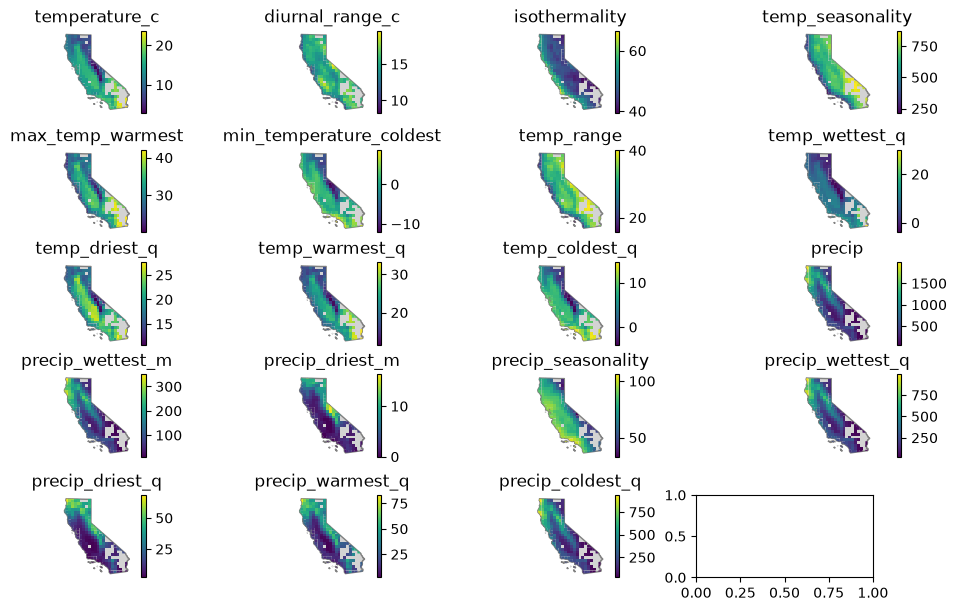

In [73]:
climate_sites = {}

# Call add_climate for each grain using all 19 layers.
for grain in GRAINS:
    sites = add_climate(sites_by_grain[grain])
    climate_sites[grain] = sites

# Report missing climate values and inspect all predictor ranges and correlations.
    print(grain, "km: sites missing climate =", sites[predictors].isna().any(axis=1).sum())

display(climate_sites[20][predictors].describe())
display(climate_sites[20][predictors].corr())
# Map temperature_c and precip at 40 km as examples of the gradients.
fig, axes = plt.subplots(5, 4, figsize=(10, 6), layout="constrained")
for ax, name in zip(axes.flat, predictors):
    california.plot(ax=ax, color="lightgray", edgecolor="gray")
    climate_sites[40].plot(ax=ax, column=name, legend=True)
    ax.set_title(name)
    ax.set_axis_off()
plt.show()

**Interpretation:** How do the environmental gradients differ from Maine's?
Why might averaging climate over larger cells conceal meaningful habitat
variation? What does a 1970–2000 climate average leave out when explaining
occurrences collected across different years?

*Your answer:* Maine's climate follows a pretty reliable gradient from south to north for most climate variables, whereas some of the climate variables in California exhibit multimodal trends due to multiple mountain ranges crossing the state. Therefore, averaging climate over larger cells may conceal these small-scale changes in climate due to elevational gradients. A long-term climate average may leave out interannual variation in climate, which could lead to interannual variation in species diversity.

## 7. Fit GDM at each grain

Reuse the lab's standard `GDM(geo=True, knots=0)` setup. Drop sites missing
climate, align their community rows, and **recompute** Jaccard pairs. `X` must
start with `xc`, `yc`, and `time_idx`, followed by all 19 climate variables, in the order in predictors.
Use zero for `time_idx` because years are pooled; it is a required placeholder.

Fit a geography-only baseline and then geography plus climate at each grain.
Report site counts, pair counts, training deviance explained, and predictor
transformation heights. Check `n_sites * (n_sites - 1) / 2` before fitting;
20/40/80 km grids keep this larger-state exercise manageable. Use all retained
sites from the supplied occurrence sample for the main comparison; do not
downsample it again.

In [58]:
model_sites = {}
model_X = {}
model_y = {}
models = {}
predictions = {}
gdm_summary = pd.DataFrame()
importance = pd.DataFrame()

# Prepare aligned X and y at each grain, as in Lab11.
for grain in GRAINS:
    sites = climate_sites[grain].dropna(subset=predictors).copy()
    community = communities[grain].loc[sites.index]
    X = sites[["xc", "yc"]].copy()
    X["time_idx"] = 0
    X[predictors] = sites[predictors]
    y = pdist(community > 0, metric="jaccard")
    model_sites[grain] = sites
    model_X[grain] = X
    model_y[grain] = y
    print(grain, "km:", len(X), "sites and", len(y), "pairs")

display(model_X[20].head())
# Fit geography-only and full GDM models, keeping model settings fixed.
for grain in GRAINS:
    X = model_X[grain]
    y = model_y[grain]
    geography_only = GDM(geo=True, knots=0).fit(X[["xc", "yc", "time_idx"]], y)

# Store the full model, predictions, deviance summaries, and importance values.
    model = GDM(geo=True, knots=0).fit(X, y)
    models[grain] = model
    predictions[grain] = model.predict(X)
    gdm_summary.loc[grain, "n_sites"] = len(X)
    gdm_summary.loc[grain, "n_pairs"] = len(y)
    gdm_summary.loc[grain, "geography_only_deviance_pct"] = 100 * geography_only.explained_
    gdm_summary.loc[grain, "training_deviance_explained_pct"] = 100 * model.explained_
    for name, value in model.predictor_importance_.items():
        importance.loc[grain, name] = value

gdm_summary.index.name = "grain_km"
importance.index.name = "grain_km"

# Display gdm_summary and importance.
display(gdm_summary)
display(importance)

20 km: 723 sites and 261003 pairs
40 km: 253 sites and 31878 pairs
80 km: 81 sites and 3240 pairs


,xc,yc,time_idx,temperature_c,diurnal_range_c,isothermality,temp_seasonality,max_temp_warmest,min_temperature_coldest,temp_range,...,temp_warmest_q,temp_coldest_q,precip,precip_wettest_m,precip_driest_m,precip_seasonality,precip_wettest_q,precip_driest_q,precip_warmest_q,precip_coldest_q
site_id,,,,,,,,,,,,,,,,,,,,,
10_26,-190000.0,-110000.0,0,13.781463,12.696052,60.599255,319.376038,24.826563,3.832474,20.994087,...,17.780729,10.027334,836.409119,175.409088,3.000000,93.258057,454.318176,11.045455,16.590910,450.863647
10_27,-190000.0,-90000.0,0,13.741483,12.179098,56.419796,366.827057,25.508621,3.869755,21.638866,...,18.445585,9.538509,851.514282,175.685715,2.771429,92.305855,454.285706,11.257143,17.142857,453.685699
10_28,-190000.0,-70000.0,0,14.440726,12.002498,55.116814,380.460205,26.009619,4.223004,21.786612,...,19.140898,9.885418,624.583313,126.750000,2.000000,90.400826,330.388885,8.416667,12.888889,327.166656
10_29,-190000.0,-50000.0,0,14.844004,11.200382,54.022446,367.577087,25.456203,4.725770,20.730434,...,19.142586,10.179401,434.115387,87.346153,1.115385,88.832817,230.192307,5.923077,9.038462,224.923080
10_30,-190000.0,-30000.0,0,14.864372,11.091510,53.493465,374.604401,25.909904,5.152510,20.757395,...,19.277126,10.141910,540.782593,112.086960,1.217391,90.384880,291.695648,7.086957,10.695652,287.260864


,n_sites,n_pairs,geography_only_deviance_pct,training_deviance_explained_pct
grain_km,,,,
20,723.0,261003.0,3.232215,9.741474
40,253.0,31878.0,9.470586,27.842751
80,81.0,3240.0,18.703866,48.766473


,temperature_c,diurnal_range_c,isothermality,temp_seasonality,max_temp_warmest,min_temperature_coldest,temp_range,temp_wettest_q,temp_driest_q,temp_warmest_q,temp_coldest_q,precip,precip_wettest_m,precip_driest_m,precip_seasonality,precip_wettest_q,precip_driest_q,precip_warmest_q,precip_coldest_q,geo
grain_km,,,,,,,,,,,,,,,,,,,,
20,0.000000,0.471173,0.198607,0.08888,0.0,0.0,0.016568,1.208578,0.00000,0.893036,0.0,0.0,0.306092,0.037413,0.583802,0.385043,0.0,0.045547,0.000000,0.197562
40,0.000000,0.466204,0.457819,0.00000,0.0,0.0,0.087448,1.977115,0.00000,0.677760,0.0,0.0,0.040751,0.119513,0.991144,0.560024,0.0,0.445251,0.000000,0.280856
80,0.469109,0.854965,0.572879,0.00000,0.0,0.0,0.000000,1.672627,0.18403,0.000000,0.0,0.0,0.094669,0.196193,0.843547,0.000000,0.0,0.013969,0.215111,0.393315


## 8. Interpret the fitted models

Plot observed versus predicted Jaccard dissimilarity for each grain. Reuse the
lab's `climate_curve` helper to show the GDM transformations of **all 19
predictors**, comparing grains on each panel. A 5-by-4 panel layout leaves room
for the 19 curves. Label predictors and partial ecological distance; the x axis
uses each variable's original WorldClim scale.

Several variables are correlated. A small transformation height does not show
that a climate process is biologically unimportant; another variable may
represent similar information.

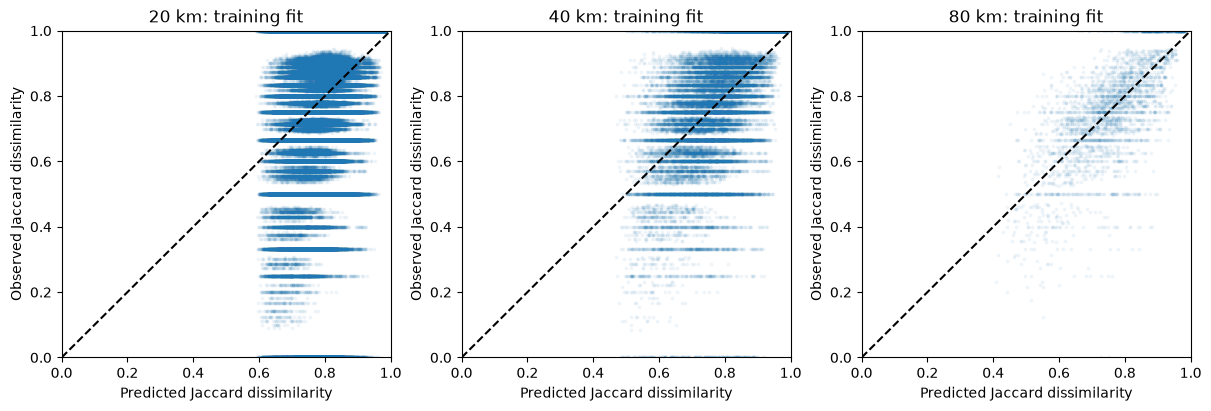

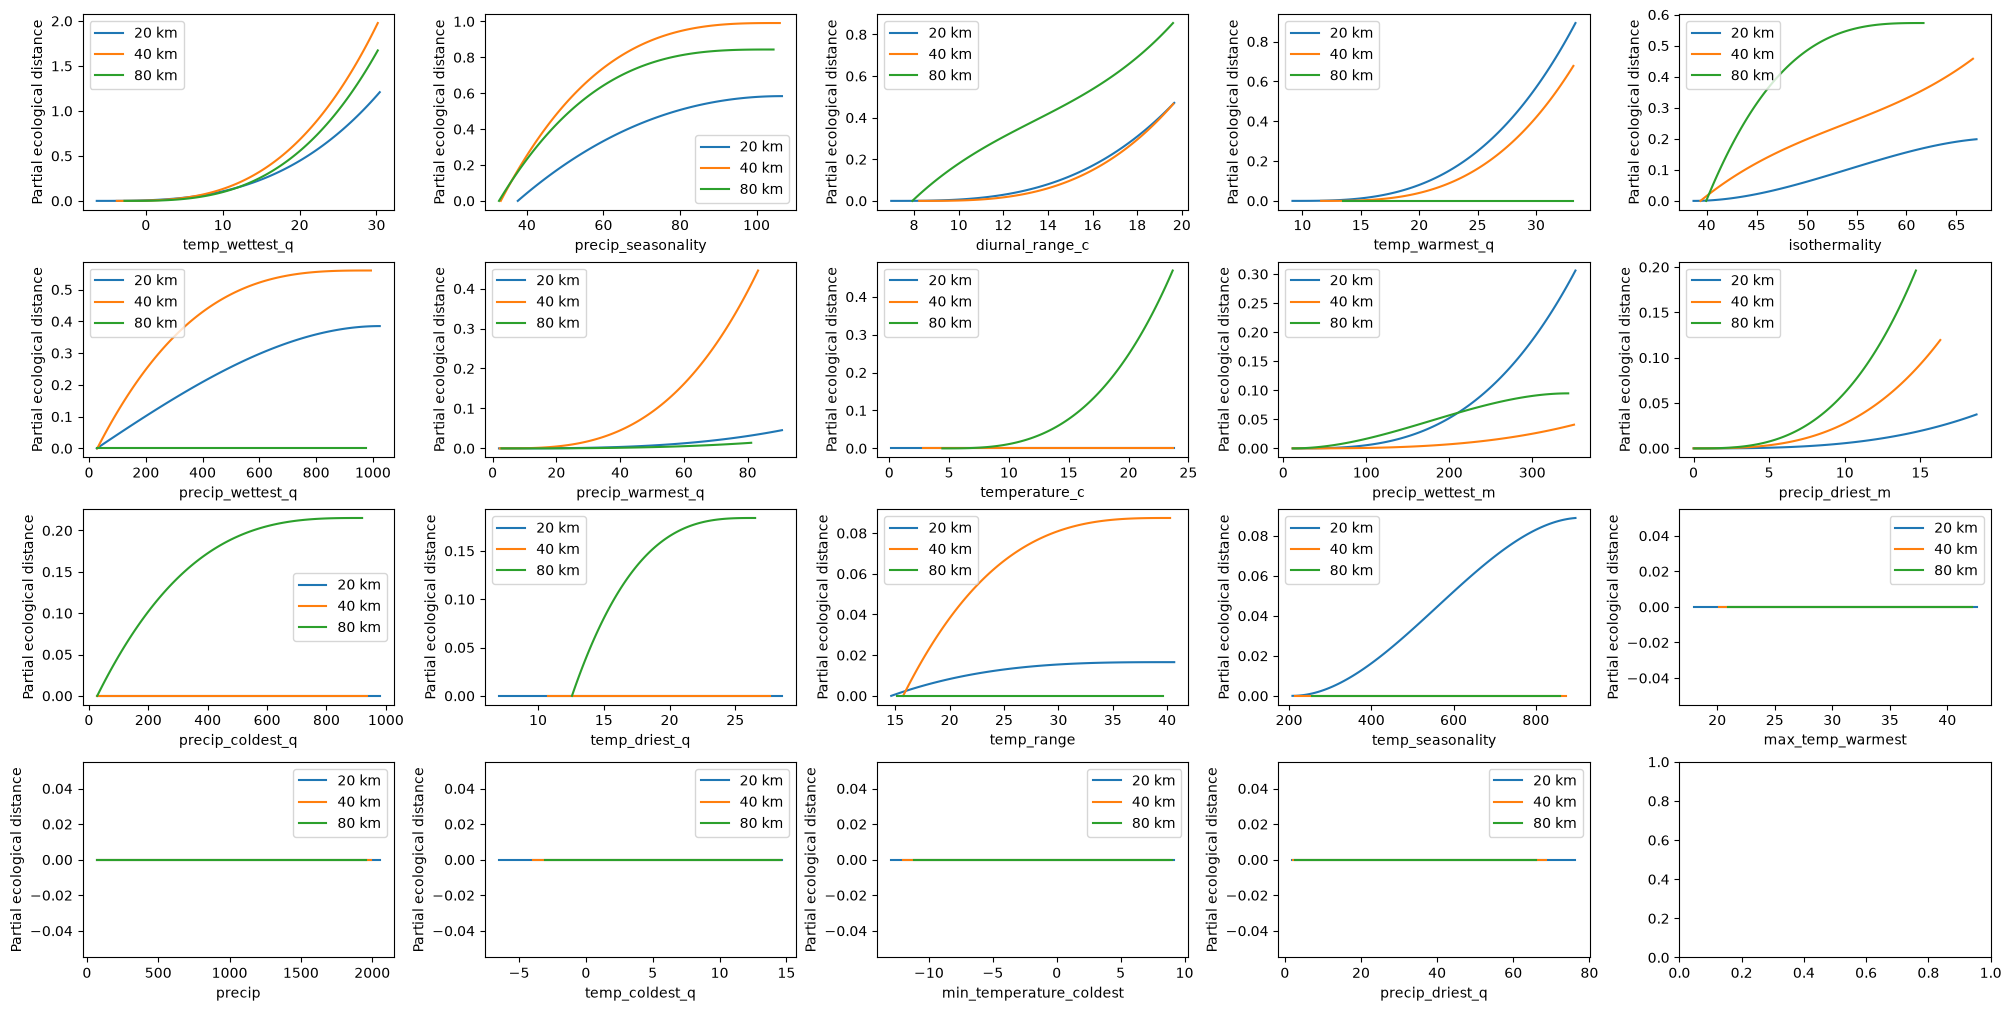

,n_sites,n_records,mean_richness,median_records_per_site,distance_similarity_rho,n_sites_gdm,n_pairs,geography_only_deviance_pct,training_deviance_explained_pct
grain_km,,,,,,,,,
20,727.0,24374.0,3.447043,7.0,-0.181919,723.0,261003.0,3.232215,9.741474
40,253.0,24374.0,5.075099,23.0,-0.314515,253.0,31878.0,9.470586,27.842751
80,81.0,24374.0,7.950617,93.0,-0.435798,81.0,3240.0,18.703866,48.766473


In [75]:
# Make the three observed-versus-predicted plots with 1:1 lines.
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, grain in zip(axes, GRAINS):
    ax.scatter(predictions[grain], model_y[grain], s=3, alpha=0.05)
    ax.plot([0, 1], [0, 1], color="black", linestyle="--")
    ax.set(title=f"{grain} km: training fit", xlabel="Predicted Jaccard dissimilarity",
           ylabel="Observed Jaccard dissimilarity", xlim=(0, 1), ylim=(0, 1))
fig.savefig(OUTPUT / "gdm_training_fit_by_grain.png", dpi=150)
plt.show()

# Reuse climate_curve from Lab11 and calculate curves for all 19 predictors.
sorted_cols = importance.sum().sort_values(ascending=False).index
importance_sorted = importance[sorted_cols].drop(columns=['geo'])
importance_sorted

def climate_curve(model, X, predictor):
    curve = pd.DataFrame(index=range(100))
    for column in X.columns:
        curve[column] = X[column].median()
    curve[predictor] = np.linspace(X[predictor].min(), X[predictor].max(), 100)
    effect = model.gdm_transform(curve).sum(axis=1)
    effect = effect - effect[0]
    return pd.DataFrame({"value": curve[predictor], "effect": effect})
    
# Plot the three grains together for each predictor in a 5-by-4 panel layout.
curves = {}

fig, axes = plt.subplots(4, 5, figsize=(20, 10), layout="constrained")
for ax, name in zip(axes.flat, importance_sorted.columns):
    for grain in GRAINS:
        curve = climate_curve(models[grain], model_X[grain], name)
        curves[(grain, name)] = curve
        ax.plot(curve.value, curve.effect, label=f"{grain} km")
    
# Label predictors and partial ecological distance; hide the unused panel.
    ax.set(xlabel=name, ylabel="Partial ecological distance")
    ax.legend()
fig.savefig(OUTPUT / "gdm_climate_curves_by_grain.png", dpi=150)
plt.show()

comparison = grain_summary.join(gdm_summary, rsuffix="_gdm")
display(comparison)

**Interpretation:** How much does adding climate improve training fit over
geography alone? Which environmental intervals show the most modeled change?
Which conclusions persist across grains? Explain why transformation heights
are not p-values, why a curve is not a habitat optimum, and why training
fit is not evidence of geographic transfer accuracy.

*Your answer:* Adding climate improved the training fit quite a bit, especially since climate and geography are as colinear in California as they are in Maine. The environmental intervals with the most modeled change are the variables that include temperature and precipitaion during the warmest and wettest quarters, precip seasonality, and diurnal range in temperature. Across grains, only a few conclusions persist: ecological distance increases with temperature during the wettest quarter, precip seasonality, diurnal temp range, and isothermality. The other variable predictions begen to break down as grain size changes. Transformation heights do not reflect statistical significants in the way that p-values do because they do not incorporate confidence or credibility intervals, and  they do not take into account null hypothesis testing. Curves do not represent habitat optimums but rather show trends in diversity that are based on publicly-available records, which are biased by sampling effort and susceptible to interannual variation, and cannot alone conclude anthing about habitat quality. Finally, training fit is not evidence of geographic transfer accuracy but rather supports the model's performance in the tested areas alone.

## 9. PCA map and biplot of expected composition

Adapt the PCA cell near the end of Lab11. Start with `pca_grain = 40`.
Sum each predictor's weighted spline components to make **19 transformed
columns**, then run PCA **without standardizing them**. This preserves the GDM
weights. Use the first two PC scores to color a California map and a PC1/PC2
scatterplot with the same color key. Report their explained-variance percentages.

Identify and label **only the two variables with the largest loading-vector
lengths across PC1 and PC2**. Calculate loadings as in the lab, then use
`sqrt(PC1_loading**2 + PC2_loading**2)` to measure each arrow's length. A signed
sum can cancel large loadings or change when an axis flips. Display the ranked
loadings table and draw the selected two arrows on the biplot. Also map those
two original climate variables to help interpret their spatial gradients.

Similar colors indicate similar climate-associated expected composition **in
the displayed two-component summary**. They do not encode richness or calibrated
Jaccard distance, and the remaining PCs may contain meaningful variation. GDM's
separate geographic-distance effect is excluded from the site-level
transformation. Each model's PCA and color scale are independent; do not compare
matching colors between states or separately fitted grains as a shared key.

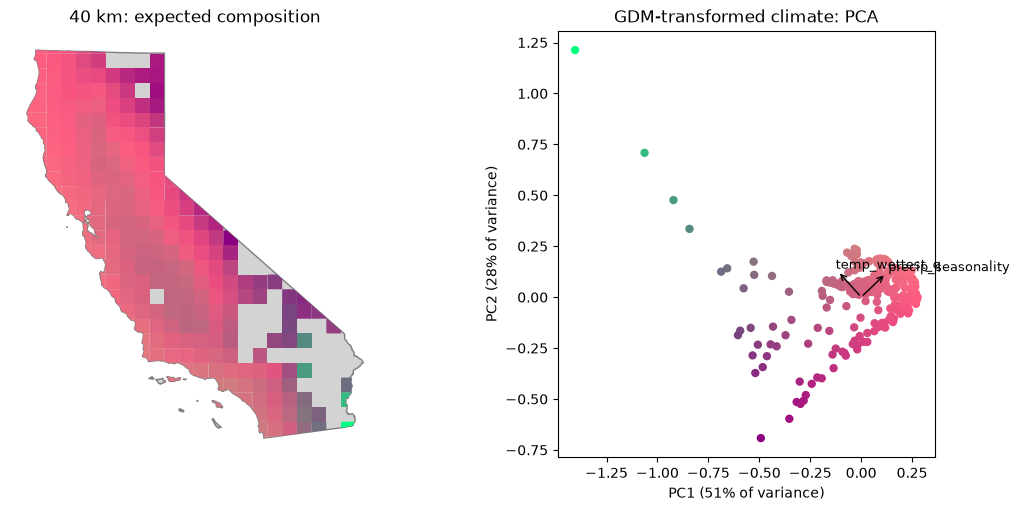

In [72]:
pca_grain = 40

# Adapt the Lab11 PCA map/biplot cell using all 19 predictors and california.
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler

X_biplot = model_X[pca_grain]
model = models[pca_grain]

# Sum each predictor's weighted spline components.
weighted_splines = model.gdm_transform(X_biplot)
n_basis = model.preprocessor_.n_spline_bases_
transformed = pd.DataFrame(index=X_biplot.index)
for i, name in enumerate(predictors):
    start = i * n_basis
    stop = start + n_basis
    transformed[name] = weighted_splines[:, start:stop].sum(axis=1)

pca = PCA(n_components=2)
scores = pca.fit_transform(transformed)
scaled_scores = MinMaxScaler(clip=True).fit_transform(scores)
colors = np.column_stack([scaled_scores, np.full(len(scores), 0.5)])

fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
california.plot(ax=axes[0], color="lightgray", edgecolor="gray")
model_sites[pca_grain].loc[X_biplot.index].plot(ax=axes[0], color=colors)
axes[0].set_title(f"{pca_grain} km: expected composition")
axes[0].set_axis_off()

axes[1].scatter(scores[:, 0], scores[:, 1], c=colors, s=25)
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

# Create a loadings table with PC1, PC2, and vector length for every predictor.
idx = np.argpartition(np.sum(np.abs(loadings), axis=1), -2)[-2:]

# Select the two longest vectors, display their names, and draw only their arrows.
for i in idx:
    vector = loadings[i]
    name = predictors[i]
    axes[1].annotate("", xy=vector, xytext=(0, 0),
                     arrowprops={"arrowstyle": "->", "color": "black"})
    axes[1].text(vector[0] * 1.1, vector[1] * 1.1, name, fontsize=9)
axes[1].set(title="GDM-transformed climate: PCA",
            xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)",
            ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
axes[1].set_aspect("equal")

# Save the PCA figure and map the two selected original climate variables.
fig.savefig(OUTPUT / f"gdm_pca_biplot_{pca_grain}_km.png", dpi=150)
plt.show()

**Interpretation:** Which two variables have the longest loading vectors?
What fraction of transformed variation do the first two PCs retain? Where does
modeled composition change most strongly, and how do the selected climate
gradients relate to that pattern? Why might the longest PCA arrows differ from
the predictors with the largest GDM transformation heights? Compare the PCA map
with richness and neighbor dissimilarity. Why do these maps answer different
questions?

*Your answer:* Temperature during the wettest quarter and precipitation seasonality have the longest loading vectors. The first two vectors retain 51% and 28% of variance, respectively. Modeled composition changes most strongly into the southeastern Mojave and Sonoran Basins, and the climate gradients show that temperature during the wettest quarter and precipitation seasonality also have the greatest differences in these areas. In this case, the longest PCA arrows are consistent with the predictors with the largest GDM transformation heights, but they may be different if the linear contribution (assessed via PCA) is lower than the non-linear contribution (assessed via GDM). The richness map does not show large variation in the regions highlighted by the PCA map, but the neighbor dissimilarity map does. This is likely because species richness is low in these areas, which may be a contributing factor to high neighbor dissimilarity, either due to turnover or replacement.

### 11. Save results and synthesize

Save the main site layers, community matrices, distance-band summaries, GDM
inputs and predictions, model-comparison tables, all 19 climate curves, the PCA loadings table, and PCA figures
in `OUTPUT`. Save sensitivity results with distinct names.

Write a **400–600 word synthesis** answering the main question: what can these
data tell us about spatial community composition in California, and which
conclusions depend on grain or sampling? Support it with numerical examples and
at least three figures. Identify one concrete additional survey or biological
dataset that would help distinguish competing explanations.

*Your synthesis:*
Across spatial grains, species richness in California consistently peaks along the coast and in central high-elevation regions. However, when the resolution is coarsened to 80 km grain size, diversity estimates are higher and more homogeneous due to spatial aggregation and increased land area per cell. Community similarity exhibits a consistent distance-decay pattern across all grain sizes: similarity declines rapidly within the first ~300 km, slows between 400 and 800 km, and declines rapidly again at the highest distances (see distance decay of similarity figure). Biologically, this reflects strong local species sharing within similar habitats followed by sharp compositional shifts across California's coastal, desert, and mountain ecosystems.

It is likely, however, that uneven sampling effort and ndestedness influence these apparent compositional patterns. At the 20m grain, high richness in the Bay Area coincides with high record counts, whereas the southern coast and mountain ranges have high richness with lower record counts (see figure showing 20 km grain size map of n_records and richness). Similarly, maps of of neigbor dissimilarity (which show high dissimilarity in the northern high-elevation forests, central Sierra Nevada mountains, and a few isolated cells throughout the state) likley do not represent pure species turnover. Low sample sizes may inflate Jaccard dissimilarity by producing nested species subsets rather than true replacement. For example, neighboring sites 6_8 and 6_1 show the highest local dissimilarities despite containing only 1 and 17 records, respectively, much like a low-richness desert community can appear highly dissimilar to a richer montane assemblage without contributing unique species.

Environmental modeling shows how spatial and temporal scale drive these patterns. Unlike Maine’s more predictable south-to-north climate gradient, California’s mountain ranges create multimodal climate distributions. Averaging climate over large cells conceals fine-scale elevational variation, while 1970–2000 means do not consider interannual variation in climate that may influence multi-year occurrence records. Adding climate to generalized dissimilarity models substantially improves training fit over geographic distance alone by disentangling climate from spatial proximity. While warmest- and wettest-quarter temperature and precipitation, precipitation seasonality, and diurnal temperature range initially show the largest modeled changes, only responses to wettest-quarter temperature, precipitation seasonality, diurnal temperature range, and isothermality persist across grains as other predictor curves break down at coarser resolutions (see figure of partial ecological distance vs. bioclim variables).

Principal component analysis further clarifies compositional changes, with the first two axes retaining 51% and 28% of the variance. Wettest-quarter temperature and precipitation seasonality exhibit the longest loading vectors, driving the strongest modeled compositional change into the southeastern Mojave and Sonoran Basins where both gradients shift sharply (see PCA map). In this case study, the longest PCA arrows align with the largest GDM transformation heights, but in other scenarios they may differ when a predictor’s linear contribution (captured by PCA) is weaker than its non-linear response (captured by GDM). Because these maps address specific aspects of biodiversity (local alpha diversity versus pairwise neighbor differences) and broad climate-driven compositional axes, richness remains uniformly low across these southeastern basins while both the PCA and neighbor-dissimilarity maps show strong spatial differentiation there. In these regions, low species counts may amplify neighbor dissimilarity through turnover or nested species.

Interpreting these models requires recognizing key limits in interpretation. GDM transformation heights are not analogous to p-values because they omit confidence or credibility intervals and formal null-hypothesis testing. Likewise, fitted response curves reflect compositional trends within opportunistic public records, which are susceptible to spatial sampling bias and interannual variation rather than true physiological habitat optima or habitat quality. Ultimately, strong training fit demonstrates explanatory performance within the sampled California landscape, not guaranteed geographic transfer accuracy to new regions.

Incorporating standardized, effort-controlled survey data would strengthen the interpretability of this analysis. By controlling for effort, low record counts and species richness can be interpreted as true non-detections, not simply the result of low effort. I'm not sure if this sort of data exists for amphibian records, but an example of this type of effort-controlled survey is the Breeding Bird Survey (BBS) which standardizes effort but ensuring that set transects are surveyed evenly during each survey period.
    
Sources: [California data provenance and GBIF instructions](../data/CA_data_README.md),
[Lab11](../labs/Lab11-SpatialCommunityComposition.ipynb),
[GDM method](https://doi.org/10.1111/j.1472-4642.2007.00341.x), and
[gdmbayes](https://github.com/butterman0/gdmbayes).

In [76]:
# Save CSVs, GeoPackages, and figures with descriptive filenames.
comparison.to_csv(OUTPUT / "grain_comparison.csv")
importance.to_csv(OUTPUT / "gdm_predictor_importance.csv")

for grain in GRAINS:
    climate_sites[grain].to_file(OUTPUT / f"sites_{grain}_km.gpkg", driver="GPKG")
    communities[grain].to_csv(OUTPUT / f"community_{grain}_km.csv")
    model_X[grain].to_csv(OUTPUT / f"gdm_inputs_{grain}_km.csv")
    pairs_by_grain[grain].to_csv(OUTPUT / f"observed_pairs_{grain}_km.csv", index=False)
    binned_decay[grain].to_csv(OUTPUT / f"distance_bands_{grain}_km.csv", index=False)

    fitted_pairs = community_pairs(model_sites[grain], communities[grain])
    fitted_pairs["predicted_jaccard"] = predictions[grain]
    fitted_pairs.to_csv(OUTPUT / f"gdm_pairs_{grain}_km.csv", index=False)
    for name in predictors:
        curves[(grain, name)].to_csv(OUTPUT / f"gdm_curve_{name}_{grain}_km.csv", index=False)

print("Results saved in", OUTPUT)

Results saved in outputs/Assignment11
